# Grid-Aware Smart EV Charging — Results & Figures

Reads the CSVs written by `scripts/run_experiments.py` (in `results/`) and saves report figures to `figures/`.
Run the experiments first; every section skips gracefully if its CSV is missing.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from evsched import PERIOD, TARIFF
from evsched.events import day_start
from acnportal.signals.tariffs import TimeOfUseTariff

RES, FIG = ROOT / "results", ROOT / "figures"
FIG.mkdir(exist_ok=True)
SHOWCASE = "2018-09-05"

# Categorical palette (fixed order, never cycled)
C = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 120, "savefig.dpi": 300, "savefig.bbox": "tight", "font.size": 10,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.spines.top": False,
    "axes.spines.right": False, "lines.linewidth": 2, "legend.frameon": False,
})

def load(name):
    p = RES / f"{name}.csv"
    return pd.read_csv(p) if p.exists() else None

LABELS = {"uncontrolled": "Uncontrolled", "edf": "EDF", "llf": "LLF", "round_robin": "Round robin",
          "mpc:cost_lp": "MPC cost (LP)", "mpc:cost_demand_lp": "MPC cost+demand (LP)",
          "mpc:valley_qp": "MPC valley (QP)", "mpc:phase_qp": "MPC phase (QP)",
          "mpc:combined_qp": "MPC combined (QP)"}
hours = lambda n: np.arange(n) * PERIOD / 60

E:\EVcharging\acnportal\acnportal\acnsim\base.py:17: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


## 1. Load profile on the showcase day (E1) — uncontrolled vs optimised

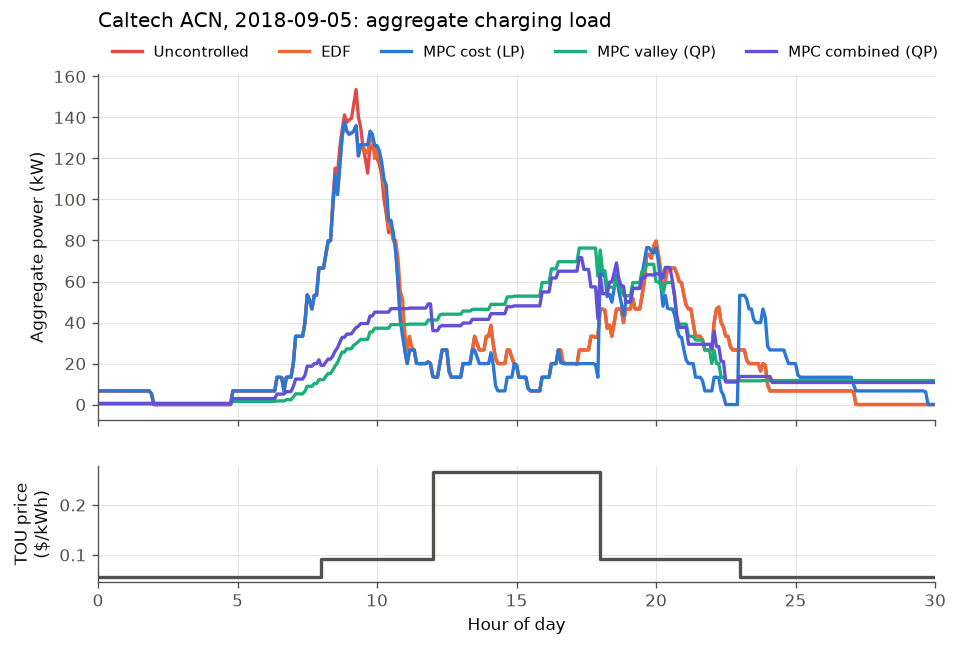

In [2]:
tr = RES / "traces" / SHOWCASE
show = [("uncontrolled", C[7]), ("edf", C[1]), ("mpc-cost_lp", C[0]), ("mpc-valley_qp", C[2]), ("mpc-combined_qp", C[6])]
prices = TimeOfUseTariff(TARIFF).get_tariffs(day_start(SHOWCASE), 30 * 60 // PERIOD, PERIOD)
fig, (ax, axp) = plt.subplots(2, 1, figsize=(9, 5.5), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
for key, color in show:
    f = tr / f"{key}_hard=False.npz"
    if f.exists():
        p = np.load(f)["power"]
        ax.plot(hours(len(p)), p, color=color, label=LABELS[key.replace("-", ":", 1)])
ax.set_ylabel("Aggregate power (kW)")
ax.legend(ncol=5, loc="lower left", bbox_to_anchor=(0, 1.0), fontsize=9)
ax.set_title(f"Caltech ACN, {SHOWCASE}: aggregate charging load", loc="left", pad=28)
axp.step(hours(len(prices)), prices, where="post", color=MUTED)
axp.set_ylabel("TOU price\n($/kWh)")
axp.set_xlabel("Hour of day")
axp.set_xlim(0, 30)
fig.savefig(FIG / "load_profile.png"); plt.show()

## 2. Phase currents — EDF vs phase-balancing QP

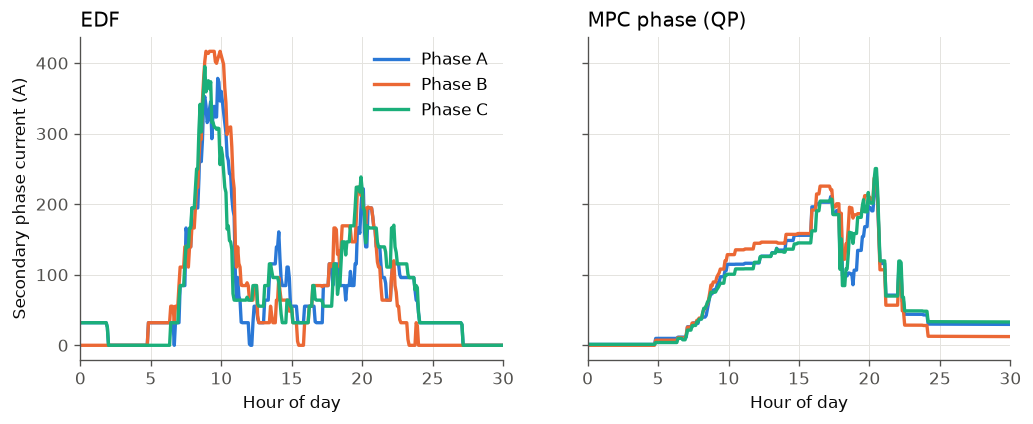

In [3]:
fig, axs = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True)
for ax, key, title in zip(axs, ["edf", "mpc-phase_qp"], ["EDF", "MPC phase (QP)"]):
    f = tr / f"{key}_hard=False.npz"
    if not f.exists():
        continue
    ph = np.load(f)["phases"]
    for i, name in enumerate("ABC"):
        ax.plot(hours(ph.shape[1]), ph[i], color=C[i], label=f"Phase {name}")
    ax.set_title(title, loc="left"); ax.set_xlabel("Hour of day"); ax.set_xlim(0, 30)
axs[0].set_ylabel("Secondary phase current (A)"); axs[0].legend()
fig.savefig(FIG / "phase_currents.png"); plt.show()

## 3. Metrics across all September 2018 weekdays (E1)

energy_cost          peak_kw            par         \
                          mean     std     mean     std   mean    std   
algo                                                                    
uncontrolled            97.270  11.867  172.843  22.466  5.245  0.748   
edf                     97.816  12.111  142.150   6.470  4.323  0.442   
llf                     97.651  12.052  143.413   6.430  4.361  0.442   
round_robin             97.618  12.008  144.186   7.349  4.390  0.472   
mpc:cost_lp             86.947  11.620  145.869   7.235  4.651  0.474   
mpc:cost_demand_lp     129.175  12.663   80.697  12.135  2.554  0.294   
mpc:valley_qp          132.356  13.114   82.388  11.591  2.725  0.295   
mpc:phase_qp           133.398  13.528   83.148   8.235  2.652  0.248   
mpc:combined_qp        124.411  12.940   79.236  10.714  2.601  0.304   

                   unbalance_mean        pct_energy_delivered         \
                             mean    std                 mean    std   
algo                                                                   
uncontrolled                0.302  0.023               99.941  0.041   
edf                         0.301  0.021               99.941  0.041   
llf                         0.301  0.022               99.941  0.041   
round_robin                 0.299  0.023               99.841  0.156   
mpc:cost_lp                 0.308  0.025               99.906  0.124   
mpc:cost_demand_lp          0.252  0.038               99.849  0.177   
mpc:valley_qp               0.319  0.034               99.809  0.233   
mpc:phase_qp                0.237  0.058               99.865  0.214   
mpc:combined_qp             0.243  0.045               99.809  0.239   

                   max_utilisation         
                              mean    std  
algo                                       
uncontrolled                 1.569  0.299  
edf                          1.000  0.000  
llf                          1.000  0.000  
round_robin                  1.000  0.000  
mpc:cost_lp                  1.000  0.000  
mpc:cost_demand_lp           0.944  0.086  
mpc:valley_qp                0.946  0.081  
mpc:phase_qp                 0.921  0.081  
mpc:combined_qp              0.898  0.115

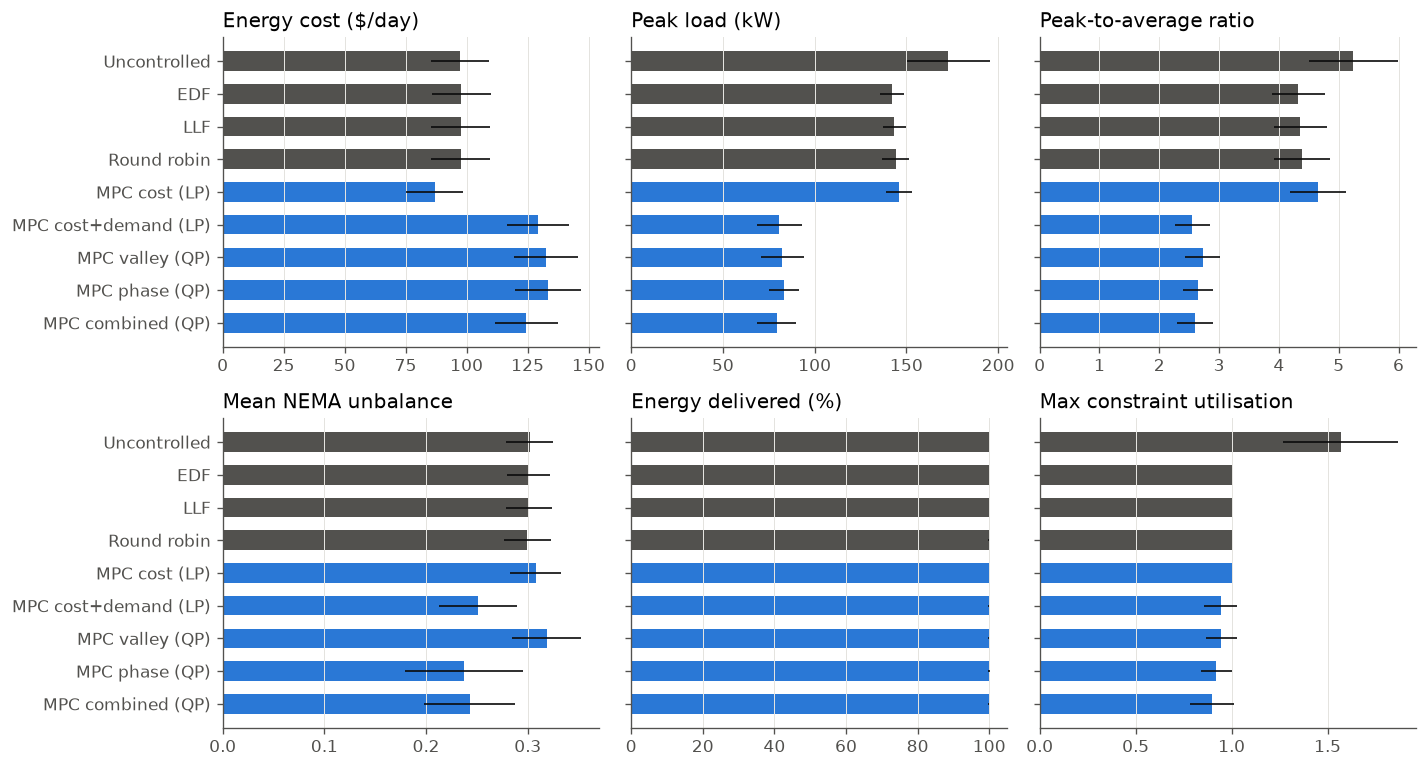

In [4]:
b = load("baselines")
if b is not None:
    metrics = {"energy_cost": "Energy cost ($/day)", "peak_kw": "Peak load (kW)", "par": "Peak-to-average ratio",
               "unbalance_mean": "Mean NEMA unbalance", "pct_energy_delivered": "Energy delivered (%)",
               "max_utilisation": "Max constraint utilisation"}
    summary = b.groupby("algo")[list(metrics)].agg(["mean", "std"])
    order = [a for a in LABELS if a in summary.index]
    display(summary.loc[order].round(3))
    summary.loc[order].round(4).to_csv(RES / "table_baselines.csv")
    fig, axs = plt.subplots(2, 3, figsize=(12, 6.5))
    for ax, (m, title) in zip(axs.flat, metrics.items()):
        mean, std = summary.loc[order, (m, "mean")], summary.loc[order, (m, "std")]
        y = np.arange(len(order))
        ax.barh(y, mean, xerr=std, color=[C[0] if o.startswith("mpc") else MUTED for o in order],
                height=0.6, error_kw={"ecolor": INK, "lw": 1})
        ax.set_yticks(y, [LABELS[o] for o in order] if ax in axs[:, 0] else [""] * len(order))
        ax.invert_yaxis(); ax.set_title(title, loc="left"); ax.grid(axis="y", visible=False)
    fig.tight_layout(); fig.savefig(FIG / "metrics_bars.png"); plt.show()

## 4. Online MPC vs offline perfect-information optimum (E3)

In [5]:
o = load("offline")
if b is not None and o is not None:
    o["preset"] = o["algo"].str.split(":").str[1]
    m = b[b.algo.str.startswith("mpc")].assign(preset=lambda d: d.algo.str.split(":").str[1])
    cols = ["energy_cost", "peak_kw", "sum_sq_load", "unbalance_mean", "pct_energy_delivered"]
    gap = m.merge(o, on=["day", "preset"], suffixes=("_mpc", "_off"))
    table = pd.DataFrame({c: (gap[f"{c}_mpc"] - gap[f"{c}_off"]).groupby(gap.preset).mean() for c in cols})
    display(table.round(3)); table.round(4).to_csv(RES / "table_mpc_vs_offline.csv")

,energy_cost,peak_kw,sum_sq_load,unbalance_mean,pct_energy_delivered
preset,,,,,
combined_qp,11.799,22.552,2938.829,0.011,-0.132
cost_demand_lp,33.556,10.051,-3169.667,-0.027,-0.091
cost_lp,-0.062,-0.044,-54.203,0.000,-0.033
phase_qp,11.032,25.238,4183.788,0.022,-0.076
valley_qp,13.207,35.187,5892.343,0.014,-0.131


## 5. Weight sweep — Pareto trade-offs (E2)

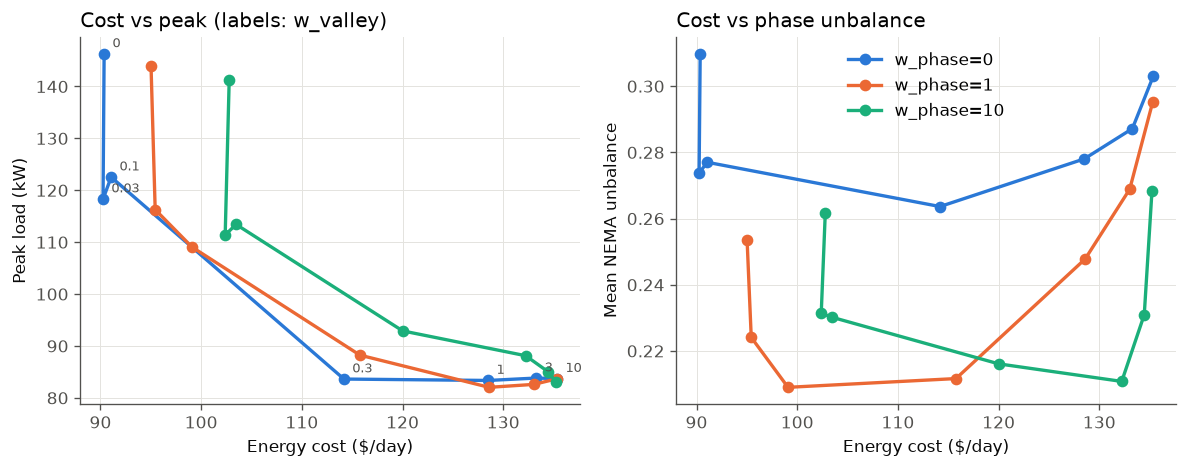

In [6]:
s = load("sweep")
if s is not None:
    agg = s.groupby(["w_valley", "w_phase"])[["energy_cost", "peak_kw", "unbalance_mean"]].mean().reset_index()
    fig, axs = plt.subplots(1, 2, figsize=(10, 4))
    for i, wp in enumerate(sorted(agg.w_phase.unique())):
        d = agg[agg.w_phase == wp].sort_values("w_valley")
        axs[0].plot(d.energy_cost, d.peak_kw, "-o", ms=6, color=C[i], label=f"w_phase={wp:g}")
        axs[1].plot(d.energy_cost, d.unbalance_mean, "-o", ms=6, color=C[i], label=f"w_phase={wp:g}")
        for _, r in d.iterrows():
            if wp == agg.w_phase.min():
                axs[0].annotate(f"{r.w_valley:g}", (r.energy_cost, r.peak_kw), textcoords="offset points",
                                xytext=(5, 4), fontsize=8, color=MUTED)
    axs[0].set(xlabel="Energy cost ($/day)", ylabel="Peak load (kW)")
    axs[1].set(xlabel="Energy cost ($/day)", ylabel="Mean NEMA unbalance")
    axs[0].set_title("Cost vs peak (labels: w_valley)", loc="left"); axs[1].set_title("Cost vs phase unbalance", loc="left")
    axs[1].legend(); fig.tight_layout(); fig.savefig(FIG / "pareto.png"); plt.show()

## 6. Soft vs hard energy constraint (E4)

In [7]:
e = load("energy")
if e is not None:
    t = e.groupby(["algo", "hard"])[["pct_energy_delivered", "unmet_kwh", "energy_cost", "peak_kw", "fallbacks"]].mean()
    display(t.round(3)); t.round(4).to_csv(RES / "table_energy.csv")

pct_energy_delivered  unmet_kwh  energy_cost  peak_kw  \
algo          hard                                                           
mpc:cost_lp   False                99.906      0.760       86.947  145.869   
              True                 99.906      0.760       86.947  145.869   
mpc:valley_qp False                99.809      1.565      132.356   82.388   
              True                 99.810      1.559      132.357   82.415   

                     fallbacks  
algo          hard              
mpc:cost_lp   False      0.000  
              True      32.053  
mpc:valley_qp False      0.000  
              True      37.579

## 7. Robust extension — price of robustness (E5)

net_cost_forecast  net_cost_mean  net_cost_p95  \
gamma_solar gamma_price                                                   
0.00        0                       49.844         54.952        62.744   
            12                      53.581         55.660        65.383   
            24                      53.208         55.569        65.026   
            48                      50.990         54.625        63.037   
0.25        0                       51.703         54.376        60.519   
            12                      50.655         53.219        61.887   
            24                      50.656         53.316        61.593   
            48                      49.769         53.295        60.405   
0.50        0                       53.307         54.512        58.867   
            12                      49.452         51.549        58.721   
            24                      49.676         51.919        58.636   
            48                      50.600         52.779        58.076   
1.00        0                       55.573         55.811        58.592   
            12                      49.495         50.330        54.897   
            24                      50.210         51.206        55.320   
            48                      53.251         53.661        56.679   

                         net_cost_worst  peak_kw  
gamma_solar gamma_price                           
0.00        0                    65.605  150.110  
            12                   68.817  144.631  
            24                   68.454  149.790  
            48                   66.291  150.109  
0.25        0                    63.127  150.111  
            12                   65.080  148.630  
            24                   64.666  150.111  
            48                   62.787  150.111  
0.50        0                    61.090  150.111  
            12                   61.504  150.102  
            24                   61.110  150.111  
            48                   59.907  150.111  
1.00        0                    60.567  150.111  
            12                   57.371  150.111  
            24                   57.626  150.111  
            48                   58.307  150.111

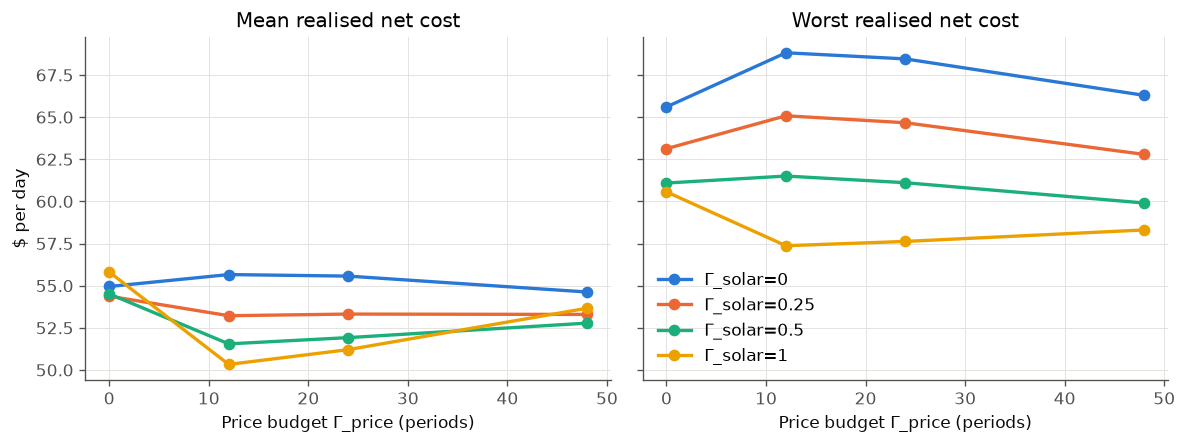

In [8]:
r = load("robust")
if r is not None:
    agg = r.groupby(["gamma_solar", "gamma_price"])[["net_cost_forecast", "net_cost_mean", "net_cost_p95", "net_cost_worst", "peak_kw"]].mean()
    display(agg.round(3)); agg.round(4).to_csv(RES / "table_robust.csv")
    fig, axs = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
    for ax, (col, title) in zip(axs, [("net_cost_mean", "Mean realised net cost"), ("net_cost_worst", "Worst realised net cost")]):
        for i, gs in enumerate(sorted(r.gamma_solar.unique())):
            d = agg.loc[gs].reset_index()
            ax.plot(d.gamma_price, d[col], "-o", ms=6, color=C[i], label=f"Γ_solar={gs:g}")
        ax.set(xlabel="Price budget Γ_price (periods)", title=title)
    axs[0].set_ylabel("$ per day"); axs[1].legend()
    fig.tight_layout(); fig.savefig(FIG / "robust.png"); plt.show()

## 8. Computational scaling (E6)

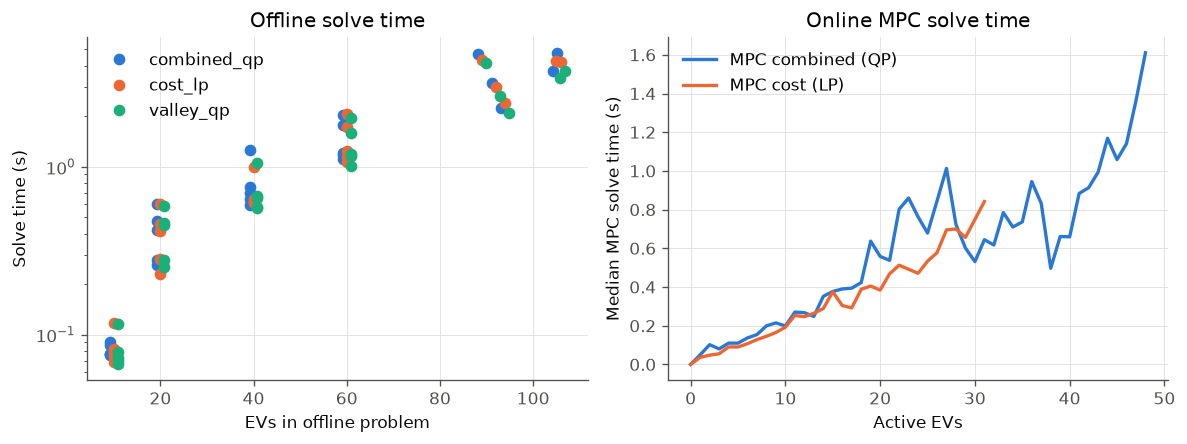

In [9]:
sc = load("scaling")
st = load("baselines_solve_stats")
fig, axs = plt.subplots(1, 2, figsize=(10, 3.8))
if sc is not None:
    for i, (preset, d) in enumerate(sc.groupby("preset")):
        jitter = (i - 1) * 0.8
        axs[0].plot(d.n_evs + jitter, d.solve_time, "o", ms=6, color=C[i], label=preset)
    axs[0].set(xlabel="EVs in offline problem", ylabel="Solve time (s)", yscale="log", title="Offline solve time")
    axs[0].legend()
if st is not None:
    for i, (algo, d) in enumerate(st[st.algo.isin(["mpc:cost_lp", "mpc:combined_qp"])].groupby("algo")):
        g = d.groupby("active_sessions").solve_time
        d = g.median()[g.size() >= 20]  # drop thin bins
        axs[1].plot(d.index, d.values, "-", color=C[i], label=LABELS[algo])
    axs[1].set(xlabel="Active EVs", ylabel="Median MPC solve time (s)", title="Online MPC solve time")
    axs[1].legend()
fig.tight_layout(); fig.savefig(FIG / "scaling.png"); plt.show()

# v2 — Billing-accurate month (E7)

The billed peak is the 15-min rolling mean. The month-to-date billed peak is carried across the 19 days, and every MPC preset pays the full demand charge on increases. A soft peak target P* applies (P90 of the August offline-optimal peaks), plus a soft finish-by deadline 30 min before departure. Batteries taper (ACN `Linear2StageBattery`), and the MPC and baselines use `SimpleRampdown`. `mpc:combined_qp+forecast` adds ghost EVs forecast from the previous 4 weeks. The offline benchmarks are joint monthly optima (perfect information, exact taper model) for the combined objective and for the bill LP.

With the demand weight set to 1 on every preset, `cost_lp` and `cost_demand_lp` become the same problem (energy + demand charge, the bill LP), so only `mpc:cost_lp` is shown.

In [10]:
from evsched.metrics import month_bill, month_summary
LABELS2 = {"uncontrolled": "Uncontrolled", "edf": "EDF", "llf": "LLF", "round_robin": "Round robin",
           "mpc:cost_lp": "MPC bill (LP)", "mpc:valley_qp": "MPC valley (QP)", "mpc:phase_qp": "MPC phase (QP)",
           "mpc:combined_qp": "MPC combined (QP)", "mpc:combined_qp+forecast": "MPC combined + forecast",
           "offline:cost_lp": "Offline bill LP (month)", "offline:combined_qp": "Offline combined (month)"}
mo, om = load("month"), load("offline_month")
dc = TimeOfUseTariff(TARIFF).get_demand_charge(day_start(SHOWCASE))
v2 = pd.concat([d for d in (mo, om) if d is not None], ignore_index=True) if mo is not None else None
if v2 is not None:
    order2 = [a for a in LABELS2 if a in set(v2.algo)]
    bills = pd.DataFrame({a: {**month_bill(v2[v2.algo == a], dc),
                              "delivered_mwh": v2[v2.algo == a].energy_delivered_kwh.sum() / 1000,
                              "bill_per_kwh": month_bill(v2[v2.algo == a], dc)["bill_15min"] / v2[v2.algo == a].energy_delivered_kwh.sum(),
                              "delivered_pct": 100 * v2[v2.algo == a].energy_delivered_kwh.sum() / v2[v2.algo == a].energy_requested_kwh.sum(),
                              "unmet_kwh_day": v2[v2.algo == a].unmet_kwh.mean(),
                              "unbalance_mean": v2[v2.algo == a].unbalance_mean.mean(),
                              "max_utilisation": v2[v2.algo == a].max_utilisation.max()} for a in order2}).T
    display(bills.round(2)); bills.round(3).to_csv(RES / "table_month.csv")

,energy,peak5_kw,peak15_kw,bill_5min,bill_15min,delivered_mwh,bill_per_kwh,delivered_pct,unmet_kwh_day,unbalance_mean,max_utilisation
uncontrolled,1873.57,195.79,191.60,4910.30,4845.25,15.38,0.31,100.09,-0.75,0.30,2.06
edf,1883.41,145.93,143.97,4146.77,4116.33,15.36,0.27,99.92,0.67,0.29,1.00
llf,1879.70,144.81,142.92,4125.76,4096.46,15.36,0.27,99.92,0.62,0.29,1.00
round_robin,1877.93,143.95,142.51,4110.59,4088.24,15.33,0.27,99.77,1.87,0.29,1.00
mpc:cost_lp,1940.76,97.52,70.27,3453.34,3030.70,15.20,0.20,98.92,8.72,0.27,1.00
mpc:valley_qp,2445.49,82.99,78.48,3732.60,3662.75,14.73,0.25,95.88,33.35,0.32,1.00
mpc:phase_qp,2434.98,79.97,68.56,3675.36,3498.28,14.87,0.24,96.76,26.22,0.24,1.00
mpc:combined_qp,2313.22,83.13,77.65,3602.56,3517.51,14.83,0.24,96.50,28.31,0.25,1.00
mpc:combined_qp+forecast,2109.24,74.60,67.43,3266.26,3155.01,14.97,0.21,97.38,21.16,0.25,1.00
offline:cost_lp,2046.16,81.00,71.16,3302.49,3149.84,15.30,0.21,99.57,3.48,0.28,1.00


## v2.1 September bill: energy + demand charge, under 5-min vs 15-min billing

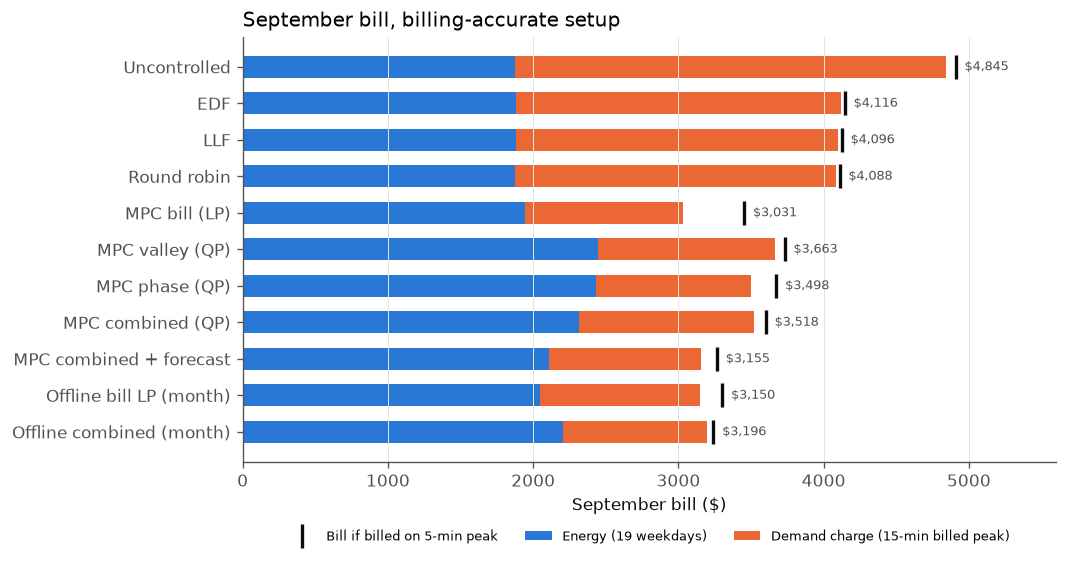

In [11]:
if v2 is not None:
    y = np.arange(len(order2))
    fig, ax = plt.subplots(figsize=(9, 4.8))
    e = bills.loc[order2, "energy"].to_numpy()
    d15 = bills.loc[order2, "bill_15min"].to_numpy() - e
    ax.barh(y, e, height=0.6, color=C[0], label="Energy (19 weekdays)")
    ax.barh(y, d15, left=e, height=0.6, color=C[1], label="Demand charge (15-min billed peak)")
    ax.plot(bills.loc[order2, "bill_5min"], y, "|", ms=14, mew=2, color=INK, label="Bill if billed on 5-min peak")
    for yi, tot, b5 in zip(y, e + d15, bills.loc[order2, "bill_5min"]):
        ax.text(max(tot, b5) + 60, yi, f"${tot:,.0f}", va="center", fontsize=8, color=MUTED)
    ax.set_yticks(y, [LABELS2[a] for a in order2]); ax.invert_yaxis(); ax.grid(axis="y", visible=False)
    ax.set_xlim(0, 5600); ax.set_xlabel("September bill ($)")
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=3, fontsize=8)
    ax.set_title("September bill, billing-accurate setup", loc="left")
    fig.tight_layout(); fig.savefig(FIG / "v2_bill.png"); plt.show()

## v2.2 Month-to-date billed peak over the 19 days

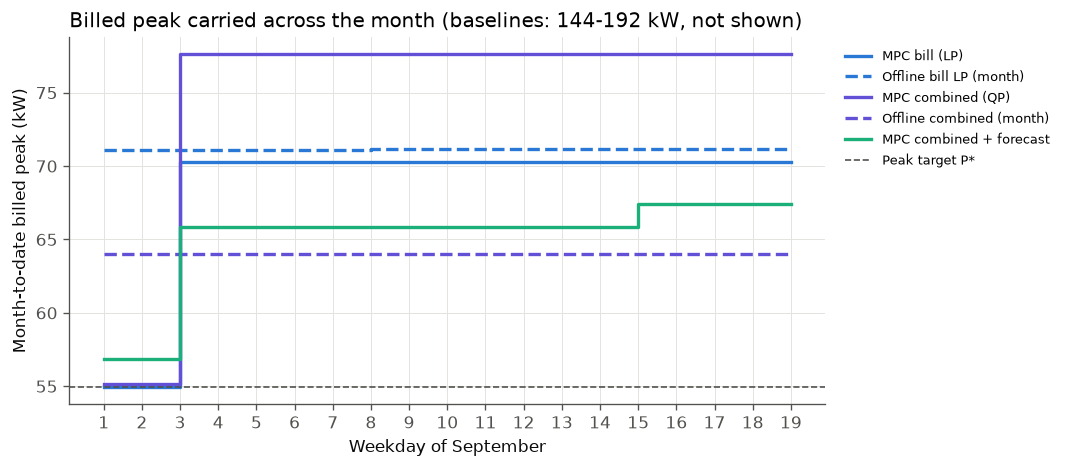

In [12]:
if v2 is not None:
    # offline benchmarks dashed in the colour of their online counterpart; baselines (144-192 kW) left out
    style2 = {"mpc:cost_lp": (C[0], "-"), "offline:cost_lp": (C[0], "--"), "mpc:combined_qp": (C[6], "-"),
              "offline:combined_qp": (C[6], "--"), "mpc:combined_qp+forecast": (C[2], "-")}
    fig, ax = plt.subplots(figsize=(9, 4))
    for a, (color, ls) in style2.items():
        if a not in order2:
            continue
        d = v2[v2.algo == a].sort_values("day")
        ax.step(np.arange(1, len(d) + 1), d.peak15_kw.cummax(), where="post", color=color, ls=ls, label=LABELS2[a])
    tf = RES / "peak_target.json"
    if tf.exists():
        import json
        ax.axhline(json.loads(tf.read_text())["peak_target_kw"], color=MUTED, ls="--", lw=1, label="Peak target P*")
    ax.set(xlabel="Weekday of September", ylabel="Month-to-date billed peak (kW)", xticks=range(1, 20))
    ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))
    ax.set_title("Billed peak carried across the month (baselines: 144-192 kW, not shown)", loc="left")
    fig.tight_layout(); fig.savefig(FIG / "v2_mtd_peak.png"); plt.show()

## v2.3 Showcase day: combined MPC with and without arrival forecast vs the offline optimum

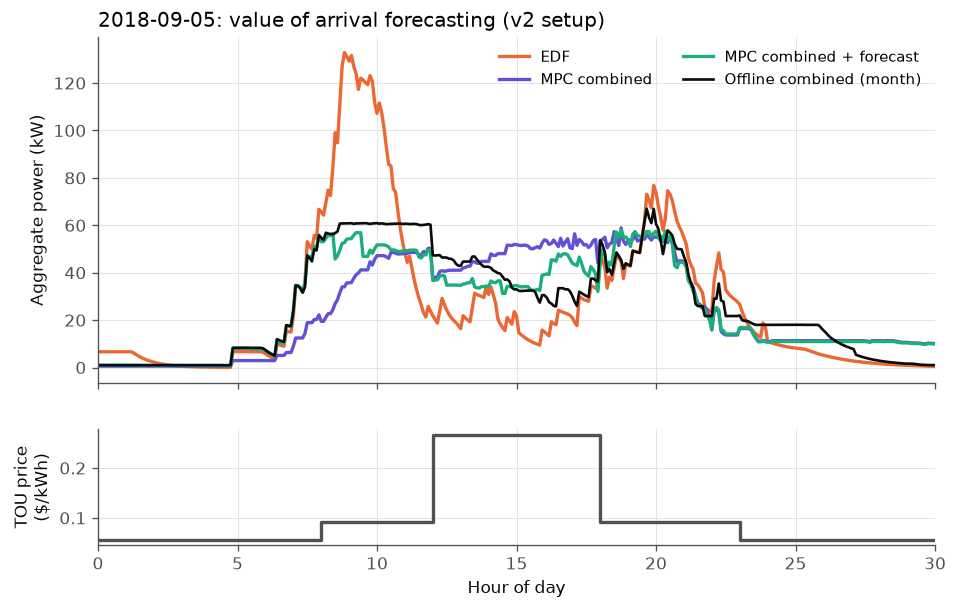

In [13]:
tr2 = RES / "traces" / "v2" / SHOWCASE
show3 = [("edf_hard=False", C[1]), ("mpc-combined_qp_hard=False", C[6]), ("mpc-combined_qp_forecast_hard=False", C[2]),
         ("offline-combined_qp", INK)]
names3 = {"edf_hard=False": "EDF", "mpc-combined_qp_hard=False": "MPC combined",
          "mpc-combined_qp_forecast_hard=False": "MPC combined + forecast", "offline-combined_qp": "Offline combined (month)"}
fig, (ax, axp) = plt.subplots(2, 1, figsize=(9, 5.5), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
for key, color in show3:
    f = tr2 / f"{key}.npz"
    if f.exists():
        p = np.load(f)["power"]
        ax.plot(hours(len(p)), p, color=color, label=names3[key], lw=1.6 if key.startswith("offline") else 2)
ax.set_ylabel("Aggregate power (kW)"); ax.legend(ncol=2, fontsize=9)
ax.set_title(f"{SHOWCASE}: value of arrival forecasting (v2 setup)", loc="left")
axp.step(hours(len(prices)), prices, where="post", color=MUTED)
axp.set_ylabel("TOU price\n($/kWh)"); axp.set_xlabel("Hour of day"); axp.set_xlim(0, 30)
fig.savefig(FIG / "v2_forecast_day.png"); plt.show()

## v2.4 Energy delivered with tapering batteries

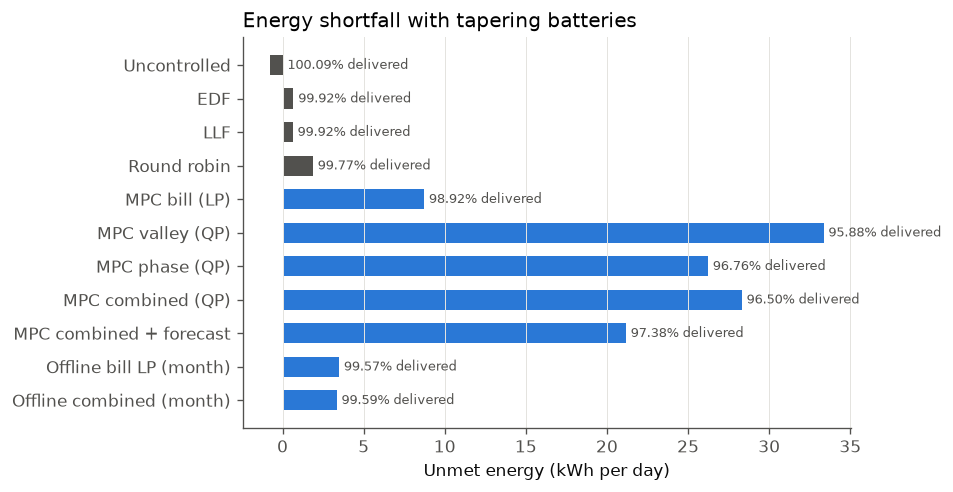

In [14]:
if v2 is not None:
    fig, ax = plt.subplots(figsize=(8, 4.2))
    y = np.arange(len(order2))
    ax.barh(y, bills.loc[order2, "unmet_kwh_day"], height=0.6, color=[C[0] if a.startswith(("mpc", "offline")) else MUTED for a in order2])
    for yi, (u, pct) in enumerate(zip(bills.loc[order2, "unmet_kwh_day"], bills.loc[order2, "delivered_pct"])):
        ax.text(max(u, 0) + 0.3, yi, f"{pct:.2f}% delivered", va="center", fontsize=8, color=MUTED)
    ax.set_yticks(y, [LABELS2[a] for a in order2]); ax.invert_yaxis(); ax.grid(axis="y", visible=False)
    ax.set_xlabel("Unmet energy (kWh per day)"); ax.set_title("Energy shortfall with tapering batteries", loc="left")
    fig.tight_layout(); fig.savefig(FIG / "v2_energy.png"); plt.show()

# v3 — Imperfect information (E8)

In E7 every online scheduler read each EV's true departure and energy at plug-in. In E8 the schedulers only see predictions; the simulator keeps the true values. Information levels:

* **perfect**: true values (E7);
* **predicted**: median stay and kWh of past sessions arriving in the same hour (28 weekdays before the day), re-predicted conditionally on overstay or on a request that turns out larger;
* **conservative**: the same, with stay = P25 and kWh = P75;
* **naive**: one global median for every EV, no updates. An EV past its guessed departure or energy is no longer charged.

Uncontrolled charging uses no information, so its E7 row stands for every level. The offline benchmark stays perfect-information. Under `PRESETS_V2`, `cost_lp` and `cost_demand_lp` are the same problem, so only `mpc:cost_lp` is shown.

In [15]:
INFO = ["perfect", "predicted", "conservative", "naive"]
INFO_C = dict(zip(INFO, [INK, C[0], C[2], C[1]]))
INFO_M = dict(zip(INFO, ["o", "s", "^", "D"]))
STOCH = ["stochastic-1", "stochastic-10", "stochastic-30", "stochastic-100"]  # stochastic MPC (expected unmet energy), MPCs only
mi, pe = load("month_info"), load("prediction_errors")
if mi is not None and mo is not None:
    e7 = mo.assign(info="perfect")
    allinfo = pd.concat([e7, mi], ignore_index=True)
    allinfo = allinfo[allinfo.algo != "mpc:cost_demand_lp"]
    order3 = [a for a in LABELS2 if a in set(mi.algo)]
    pred_cols = ["pred_stay_mae_min", "pred_kwh_mae", "pct_overstay", "pct_under_kwh", "stay_updates", "kwh_updates"]
    recs = []
    for (a, lvl), d in allinfo.groupby(["algo", "info"]):
        b = month_bill(d, dc)
        kwh = d.energy_delivered_kwh.sum()
        recs.append({"algo": a, "info": lvl if a != "uncontrolled" else "any", "bill_15min": b["bill_15min"],
                     "energy": b["energy"], "peak15_kw": d.peak15_kw.max(), "delivered_mwh": kwh / 1000,
                     "delivered_pct": 100 * kwh / d.energy_requested_kwh.sum(), "bill_per_kwh": b["bill_15min"] / kwh,
                     "unmet_kwh_day": d.unmet_kwh.mean(), "max_utilisation": d.max_utilisation.max(),
                     **{c: d[c].mean() for c in pred_cols if c in d}})
    tab = pd.DataFrame(recs)
    ref = tab[tab["info"].isin(["perfect", "any"])].set_index("algo")
    tab["d_bill"] = tab.bill_15min - tab.algo.map(ref.bill_15min)
    tab["d_delivered_pct"] = tab.delivered_pct - tab.algo.map(ref.delivered_pct)
    tab["algo"] = pd.Categorical(tab.algo, [a for a in LABELS2 if a in set(tab.algo)])
    tab["info"] = pd.Categorical(tab["info"], ["any"] + INFO + STOCH)
    tab = tab.sort_values(["algo", "info"]).reset_index(drop=True)
    display(tab.round(2)); tab.round(3).to_csv(RES / "table_info.csv", index=False)

,algo,info,bill_15min,energy,peak15_kw,delivered_mwh,delivered_pct,bill_per_kwh,unmet_kwh_day,max_utilisation,pred_stay_mae_min,pred_kwh_mae,pct_overstay,pct_under_kwh,stay_updates,kwh_updates,d_bill,d_delivered_pct
0,uncontrolled,any,4845.25,1873.57,191.60,15.38,100.09,0.31,-0.75,2.06,NaN,NaN,NaN,NaN,NaN,NaN,0.00,0.00
1,edf,perfect,4116.33,1883.41,143.97,15.36,99.92,0.27,0.67,1.00,NaN,NaN,NaN,NaN,NaN,NaN,0.00,0.00
2,edf,predicted,4059.19,1879.26,140.55,15.32,99.68,0.26,2.57,1.00,155.06,4.47,49.22,51.08,30.58,105.47,-57.14,-0.23
3,edf,conservative,4059.30,1883.79,140.26,15.35,99.87,0.26,1.06,1.00,191.00,5.55,73.42,26.56,107.84,49.95,-57.03,-0.05
4,edf,naive,3504.92,1255.80,145.01,10.36,67.43,0.34,263.42,1.00,212.55,4.55,49.77,51.11,0.00,0.00,-611.41,-32.48
5,llf,perfect,4096.46,1879.70,142.92,15.36,99.92,0.27,0.62,1.00,NaN,NaN,NaN,NaN,NaN,NaN,0.00,0.00
6,llf,predicted,4036.53,1879.28,139.09,15.31,99.65,0.26,2.84,1.00,155.06,4.47,49.22,51.08,30.63,105.42,-59.93,-0.27
7,llf,conservative,4138.39,1882.32,145.46,15.34,99.80,0.27,1.66,1.00,191.00,5.55,73.42,26.56,108.74,49.63,41.93,-0.13
8,llf,naive,3453.27,1255.60,141.69,10.36,67.42,0.33,263.50,1.00,212.55,4.55,49.77,51.11,0.00,0.00,-643.19,-32.50
9,round_robin,perfect,4088.24,1877.93,142.51,15.33,99.77,0.27,1.87,1.00,NaN,NaN,NaN,NaN,NaN,NaN,0.00,0.00


## v3.1 Bill, energy delivered and billed peak per scheduler and information level

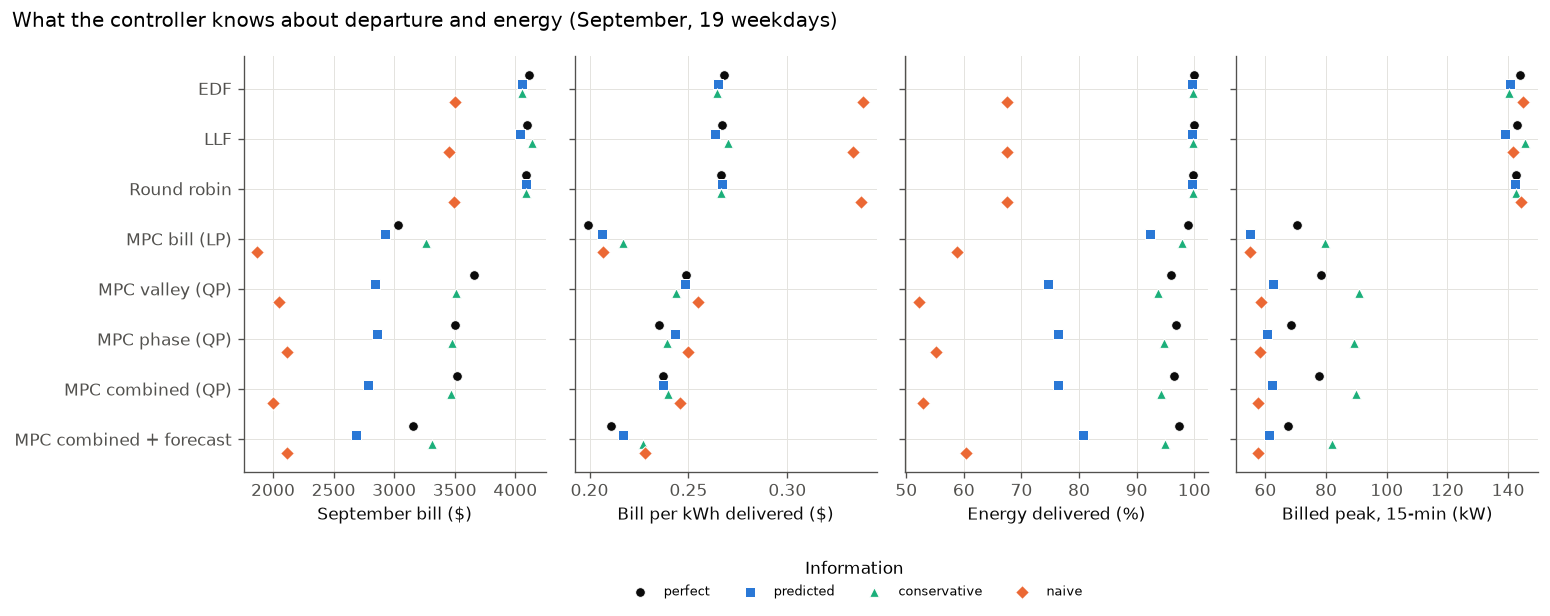

In [16]:
if mi is not None:
    fig, axs = plt.subplots(1, 4, figsize=(13, 4.8), sharey=True)
    y = {a: i for i, a in enumerate(order3)}
    dodge = dict(zip(INFO, [-0.27, -0.09, 0.09, 0.27]))  # one row per scheduler, levels offset vertically
    for ax, col, xl in zip(axs, ["bill_15min", "bill_per_kwh", "delivered_pct", "peak15_kw"],
                           ["September bill ($)", "Bill per kWh delivered ($)", "Energy delivered (%)",
                            "Billed peak, 15-min (kW)"]):
        for i in range(len(order3)):
            ax.axhline(i, color=GRID, lw=0.6, zorder=0)
        for lvl in INFO:
            d = tab[(tab["info"] == lvl) & tab.algo.isin(order3)]
            ax.scatter(d[col], [y[a] + dodge[lvl] for a in d.algo], s=34, marker=INFO_M[lvl], color=INFO_C[lvl],
                       edgecolor="white", linewidth=0.6, zorder=3, label=lvl)
        ax.set_xlabel(xl); ax.grid(axis="y", visible=False)
    axs[0].set_yticks(range(len(order3)), [LABELS2[a] for a in order3]); axs[0].invert_yaxis()
    fig.legend(*axs[0].get_legend_handles_labels(), title="Information", loc="lower center",
               bbox_to_anchor=(0.55, -0.06), ncol=4, fontsize=8)
    fig.suptitle("What the controller knows about departure and energy (September, 19 weekdays)", x=0.01, ha="left")
    fig.tight_layout(rect=(0, 0.06, 1, 1)); fig.savefig(FIG / "v3_info_cost.png"); plt.show()

## v3.2 Plug-in prediction errors (predicted − true), all September sessions

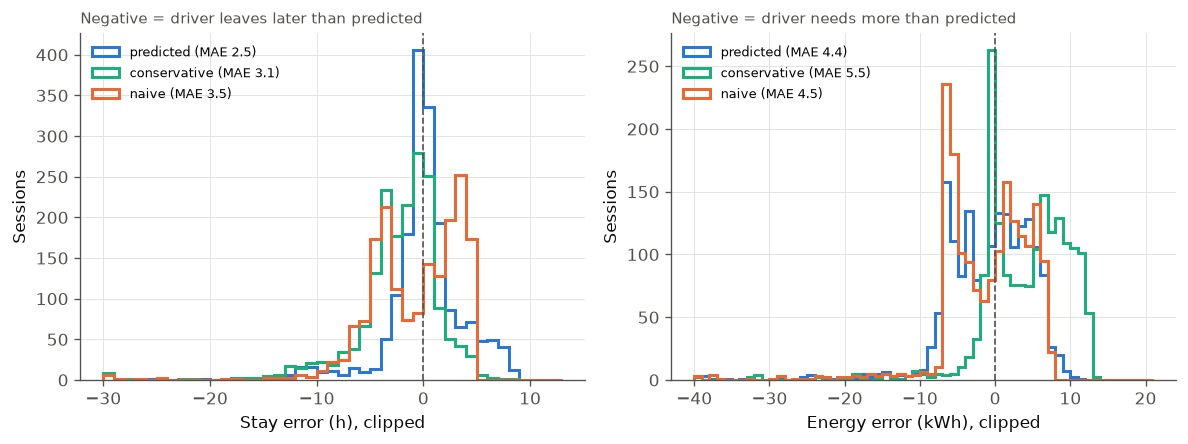

In [17]:
if pe is not None:
    fig, axs = plt.subplots(1, 2, figsize=(10, 3.8))
    pe["stay_err_h"] = (pe.pred_stay - pe.true_stay) * PERIOD / 60
    pe["kwh_err"] = pe.pred_kwh - pe.true_kwh
    for ax, col, bins, xl in zip(axs, ["stay_err_h", "kwh_err"], [np.arange(-30, 14, 1), np.arange(-40, 22, 1)],
                                 ["Stay error (h)", "Energy error (kWh)"]):
        for lvl in ["predicted", "conservative", "naive"]:
            v = pe.loc[pe["info"] == lvl, col].clip(bins[0], bins[-1])
            ax.hist(v, bins=bins, histtype="step", lw=1.8, color=INFO_C[lvl],
                    label=f"{lvl} (MAE {v.abs().mean():.1f})")
        ax.axvline(0, color=MUTED, lw=1, ls="--"); ax.set_xlabel(xl + ", clipped"); ax.set_ylabel("Sessions")
        ax.legend(fontsize=8, loc="upper left")
    axs[0].set_title("Negative = driver leaves later than predicted", loc="left", fontsize=9, color=MUTED)
    axs[1].set_title("Negative = driver needs more than predicted", loc="left", fontsize=9, color=MUTED)
    fig.tight_layout(); fig.savefig(FIG / "v3_pred_error.png"); plt.show()

## v3.3 Showcase day: combined MPC + forecast under each information level

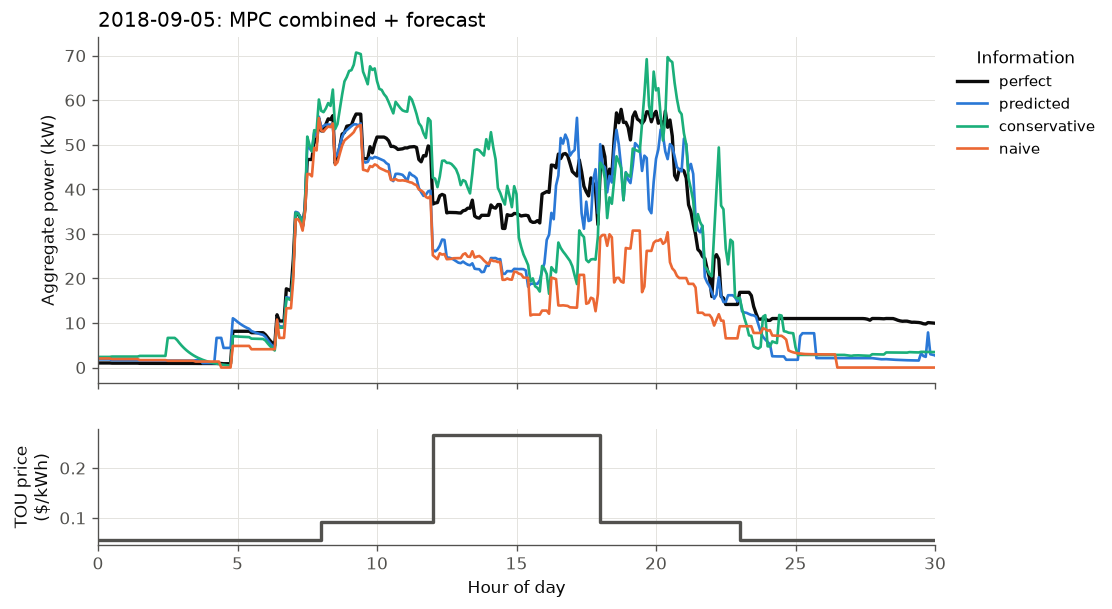

In [18]:
key = "mpc-combined_qp_forecast_hard=False.npz"
files = {"perfect": RES / "traces" / "v2" / SHOWCASE / key,
         **{lvl: RES / "traces" / "v3" / lvl / SHOWCASE / key for lvl in INFO[1:]}}
fig, (ax, axp) = plt.subplots(2, 1, figsize=(9, 5.5), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
for lvl, f in files.items():
    if f.exists():
        p = np.load(f)["power"]
        ax.plot(hours(len(p)), p, color=INFO_C[lvl], label=lvl, lw=2 if lvl == "perfect" else 1.6)
ax.set_ylabel("Aggregate power (kW)"); ax.legend(fontsize=9, title="Information", loc="upper left", bbox_to_anchor=(1.01, 1))
ax.set_title(f"{SHOWCASE}: MPC combined + forecast", loc="left")
axp.step(hours(len(prices)), prices, where="post", color=MUTED)
axp.set_ylabel("TOU price\n($/kWh)"); axp.set_xlabel("Hour of day"); axp.set_xlim(0, 30)
fig.savefig(FIG / "v3_day.png"); plt.show()

## v3.4 Stochastic MPC: expected unmet energy over the (stay, kWh) distribution

The `stochastic-w` levels keep the median predictions for everything else but let each MPC minimise the expected unmet energy over up to 20 historical (stay, kWh) scenarios of the EV's arrival hour, conditioned on what has been observed (still plugged in, not finished), at weight w $/kWh. The finish-by term is dropped. Each MPC's points are joined in the order w = 1 → 10 → 30 → 100.

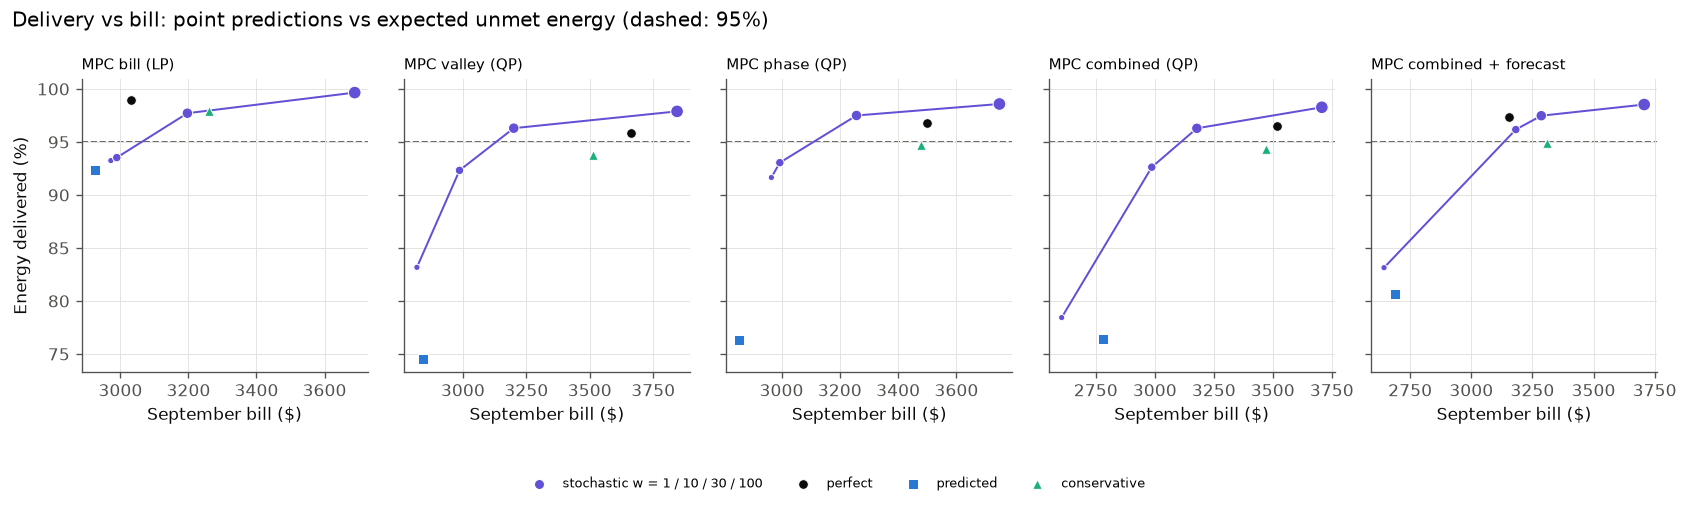

In [19]:
if mi is not None and mi["info"].isin(STOCH).any():
    st_algos = [a for a in order3 if a.startswith("mpc")]
    LEVEL_STYLE = {"perfect": (INK, "o"), "predicted": (C[0], "s"), "conservative": (C[2], "^")}
    fig, axs = plt.subplots(1, len(st_algos), figsize=(14, 3.9), sharey=True)
    for ax, a in zip(axs, st_algos):
        d = tab[tab.algo == a].set_index("info")
        s_ = d.loc[[l for l in STOCH if l in d.index]]
        ax.plot(s_.bill_15min, s_.delivered_pct, color=C[6], lw=1.2, zorder=2)
        ax.scatter(s_.bill_15min, s_.delivered_pct, s=[14, 26, 40, 58][:len(s_)], color=C[6], edgecolor="white",
                   linewidth=0.6, zorder=3, label="stochastic w = 1 / 10 / 30 / 100")
        for lvl, (col, mk) in LEVEL_STYLE.items():
            if lvl in d.index:
                ax.scatter(d.loc[lvl, "bill_15min"], d.loc[lvl, "delivered_pct"], s=34, marker=mk, color=col,
                           edgecolor="white", linewidth=0.6, zorder=4, label=lvl)
        ax.axhline(95, color=MUTED, lw=1, ls="--", zorder=1)
        ax.set_title(LABELS2[a], loc="left", fontsize=9); ax.set_xlabel("September bill ($)")
    axs[0].set_ylabel("Energy delivered (%)")
    fig.legend(*axs[0].get_legend_handles_labels(), loc="lower center", bbox_to_anchor=(0.5, -0.07), ncol=4, fontsize=8)
    fig.suptitle("Delivery vs bill: point predictions vs expected unmet energy (dashed: 95%)", x=0.01, ha="left")
    fig.tight_layout(rect=(0, 0.06, 1, 1)); fig.savefig(FIG / "v3_stochastic_frontier.png"); plt.show()

## v3.5 Showcase day: who gets their energy (combined MPC + forecast, predicted vs stochastic-10)

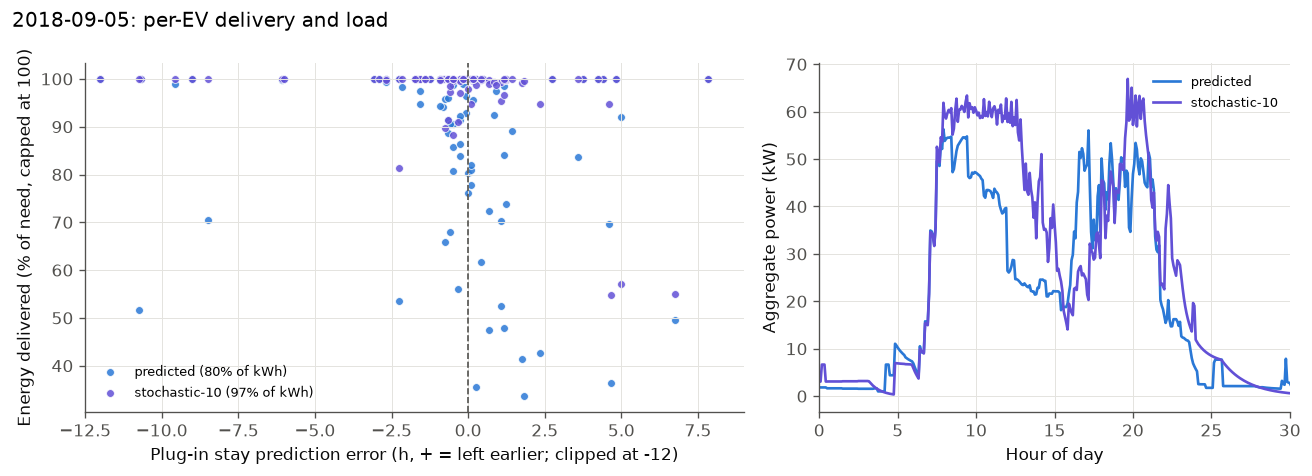

In [20]:
se = load("stochastic_showcase")
if se is not None:
    fig, axs = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [1.4, 1]})
    for lvl, col in [("predicted", C[0]), ("stochastic-10", C[6])]:
        d = se[se["info"] == lvl]
        # a few ~1 kWh requests overshoot by part of a period; a 2-day stay sits off the left edge
        axs[0].scatter(d.stay_err_h.clip(lower=-12), (100 * d.delivered_kwh / d.requested_kwh).clip(upper=100), s=22, color=col, alpha=0.85,
                       edgecolor="white", linewidth=0.5, label=f"{lvl} ({100 * d.delivered_kwh.sum() / d.requested_kwh.sum():.0f}% of kWh)")
    axs[0].axvline(0, color=MUTED, lw=1, ls="--"); axs[0].set_xlim(-12.5, 9)
    axs[0].set_xlabel("Plug-in stay prediction error (h, + = left earlier; clipped at -12)")
    axs[0].set_ylabel("Energy delivered (% of need, capped at 100)"); axs[0].legend(fontsize=8, loc="lower left")
    key = "mpc-combined_qp_forecast_hard=False.npz"
    for lvl, col in [("predicted", C[0]), ("stochastic-10", C[6])]:
        f = RES / "traces" / "v3" / lvl / SHOWCASE / key
        if f.exists():
            p = np.load(f)["power"]
            axs[1].plot(hours(len(p)), p, color=col, lw=1.6, label=lvl)
    axs[1].set_xlim(0, 30); axs[1].set_xlabel("Hour of day"); axs[1].set_ylabel("Aggregate power (kW)")
    axs[1].legend(fontsize=8)
    fig.suptitle(f"{SHOWCASE}: per-EV delivery and load", x=0.01, ha="left")
    fig.tight_layout(); fig.savefig(FIG / "v3_stochastic_day.png"); plt.show()

# v4 — On-site solar (E9)

E9 adds a 50 kW behind-the-meter PV array to the E7 month and reruns every MPC (no heuristics) with the bill on **net import** = max(EV load − PV, 0). PV surplus earns nothing. Weather is synthetic and seeded by date: each day draws a sky type (clear / partly cloudy / overcast) and a daily clearness, with AR(1) passing clouds. The MPC sees a day-ahead forecast blended with the last measured PV (persistence nowcast, 2 h decay). Information levels: **perfect** (E7) and **predicted** (E8 median). The offline optima know the realised PV.

In [21]:
LEVEL_C = {"perfect": INK, "predicted": C[0]}
SKY_C = {"clear": C[3], "partly": C[0], "overcast": C[6]}
ms, mw = load("month_solar"), load("solar_weather")
if ms is not None:
    nopv = pd.concat([mo.assign(info="perfect"), mi[mi["info"] != "perfect"], om.assign(info="perfect")],
                     ignore_index=True)
    recs = []
    for (a, lvl), d in ms.groupby(["algo", "info"]):
        ref = nopv[(nopv.algo == a) & (nopv["info"] == lvl)]
        b0 = month_bill(ref, dc) if len(ref) else {"bill_15min": np.nan}  # +fix MPCs: PV only
        kwh = d.energy_delivered_kwh.sum()
        bill = d.import_cost.sum() + dc * d.import_peak15_kw.max()
        recs.append({"algo": a, "info": lvl, "bill_nopv": b0["bill_15min"], "bill_pv": bill,
                     "energy_pv": d.import_cost.sum(), "demand_pv": dc * d.import_peak15_kw.max(),
                     "peak15_nopv": ref.peak15_kw.max() if len(ref) else np.nan, "import_peak15_kw": d.import_peak15_kw.max(),
                     "gross_peak15_kw": d.peak15_kw.max(), "delivered_pct_nopv": 100 * ref.energy_delivered_kwh.sum() / ref.energy_requested_kwh.sum() if len(ref) else np.nan,
                     "delivered_pct": 100 * kwh / d.energy_requested_kwh.sum(), "import_mwh": d.import_kwh.sum() / 1000,
                     "pv_used_mwh": d.pv_used_kwh.sum() / 1000, "self_consumption": d.pv_used_kwh.sum() / d.pv_kwh.sum(),
                     "self_sufficiency": d.pv_used_kwh.sum() / kwh, "bill_per_kwh": bill / kwh,
                     "max_utilisation": d.max_utilisation.max(), "days": len(d)})
    sol = pd.DataFrame(recs)
    sol["d_bill"] = sol.bill_pv - sol.bill_nopv
    sol["d_bill_pct"] = 100 * sol.d_bill / sol.bill_nopv
    LABELS4 = {**{a: LABELS2[a] for a in LABELS2 if a.startswith("mpc") and a != "mpc:cost_demand_lp"},
               "mpc:cost_lp+forecast+fix": "MPC bill (LP) + fixed forecast",
               "mpc:combined_qp+forecast+fix": "MPC combined + fixed forecast",
               "offline:cost_lp": "Offline bill LP", "offline:combined_qp": "Offline combined"}
    order4 = [a for a in LABELS4 if a in set(sol.algo)]
    sol["algo"] = pd.Categorical(sol.algo, order4)
    sol["info"] = pd.Categorical(sol["info"], ["perfect", "predicted", "conservative", "stochastic-30"])
    sol = sol.sort_values(["algo", "info"]).reset_index(drop=True)
    display(sol.round(2)); sol.round(3).to_csv(RES / "table_solar.csv", index=False)

,algo,info,bill_nopv,bill_pv,energy_pv,demand_pv,peak15_nopv,import_peak15_kw,gross_peak15_kw,delivered_pct_nopv,delivered_pct,import_mwh,pv_used_mwh,self_consumption,self_sufficiency,bill_per_kwh,max_utilisation,days,d_bill,d_bill_pct
0,mpc:cost_lp,perfect,3030.70,2513.77,1006.12,1507.65,70.27,97.21,132.13,98.92,98.59,9.13,6.02,0.98,0.40,0.17,1.0,19,-516.94,-17.06
1,mpc:cost_lp,predicted,2923.89,2235.02,885.69,1349.33,54.93,87.00,112.44,92.33,84.26,6.99,5.96,0.97,0.46,0.17,1.0,19,-688.87,-23.56
2,mpc:cost_lp,conservative,3261.28,2359.58,983.93,1375.65,79.74,88.69,123.02,97.91,97.42,9.56,5.41,0.88,0.36,0.16,1.0,19,-901.70,-27.65
3,mpc:cost_lp,stochastic-30,3196.88,1994.14,984.32,1009.83,72.60,65.11,105.17,97.71,98.19,9.85,5.24,0.85,0.35,0.13,1.0,19,-1202.74,-37.62
4,mpc:valley_qp,perfect,3662.75,2331.61,1298.34,1033.26,78.48,66.62,85.29,95.88,96.20,8.76,6.02,0.98,0.41,0.16,1.0,19,-1331.15,-36.34
5,mpc:valley_qp,predicted,2844.14,1647.52,795.59,851.93,62.55,54.93,78.83,74.57,74.68,5.67,5.81,0.94,0.51,0.14,1.0,19,-1196.62,-42.07
6,mpc:valley_qp,conservative,3514.22,2197.96,999.20,1198.77,90.88,77.29,99.10,93.77,93.42,8.55,5.80,0.94,0.40,0.15,1.0,19,-1316.25,-37.46
7,mpc:valley_qp,stochastic-30,3200.37,1933.66,957.78,975.88,70.82,62.92,101.22,96.30,97.24,9.47,5.48,0.89,0.37,0.13,1.0,19,-1266.72,-39.58
8,mpc:phase_qp,perfect,3498.28,2300.09,1305.88,994.21,68.56,64.10,91.79,96.76,97.19,8.84,6.10,0.99,0.41,0.15,1.0,19,-1198.19,-34.25
9,mpc:phase_qp,predicted,2855.14,1694.40,843.73,850.67,60.54,54.85,84.43,76.32,76.64,5.94,5.83,0.95,0.50,0.14,1.0,19,-1160.74,-40.65


## v4.1 Synthetic September weather

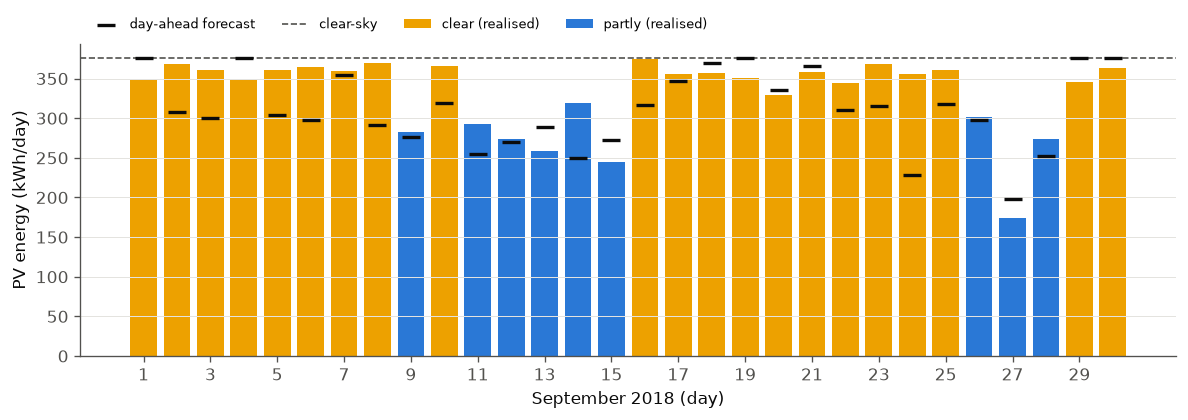

In [22]:
if mw is not None:
    w = mw[mw.date.str.startswith("2018-09")].reset_index(drop=True)
    fig, ax = plt.subplots(figsize=(10, 3.6))
    x = np.arange(len(w)) + 1
    for sky, color in SKY_C.items():
        m = w.sky == sky
        if m.any():
            ax.bar(x[m], w.pv_kwh[m], width=0.8, color=color, label=f"{sky} (realised)")
    ax.scatter(x, w.forecast_kwh, marker="_", s=120, color=INK, linewidth=2, zorder=3, label="day-ahead forecast")
    ax.axhline(w.clear_sky_kwh.iloc[0], color=MUTED, lw=1, ls="--", label="clear-sky")
    ax.set_xticks(x[::2]); ax.set_xlabel("September 2018 (day)"); ax.set_ylabel("PV energy (kWh/day)")
    ax.legend(fontsize=8, ncol=4, loc="lower left", bbox_to_anchor=(0, 1.0))
    ax.grid(axis="x", visible=False)
    fig.tight_layout(); fig.savefig(FIG / "v4_weather.png"); plt.show()

## v4.2 Bill, billed peak and energy delivered, without and with 50 kW PV

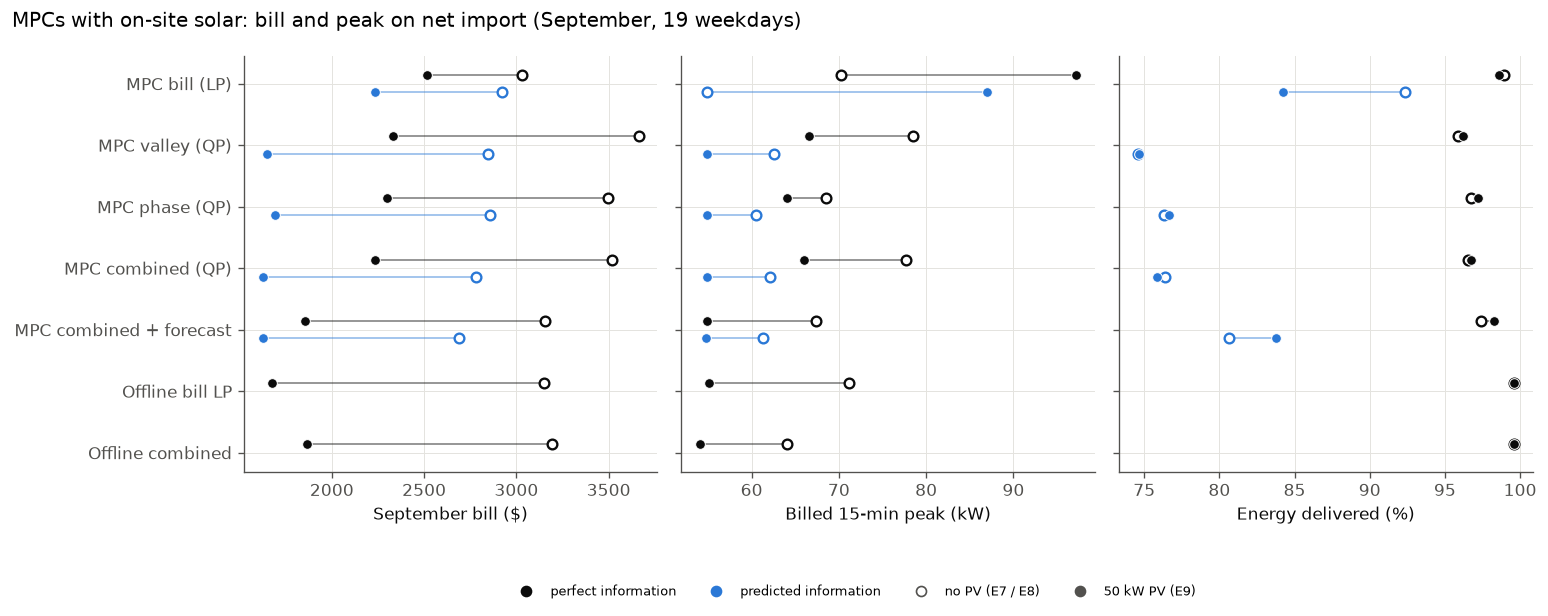

In [23]:
if ms is not None:
    order4b = [a for a in order4 if "+fix" not in a]
    fig, axs = plt.subplots(1, 3, figsize=(13, 4.8), sharey=True)
    y = {a: i for i, a in enumerate(order4b)}
    dodge = {"perfect": -0.14, "predicted": 0.14}
    for ax, (c0, c1), xl in zip(axs, [("bill_nopv", "bill_pv"), ("peak15_nopv", "import_peak15_kw"),
                                      ("delivered_pct_nopv", "delivered_pct")],
                                ["September bill ($)", "Billed 15-min peak (kW)", "Energy delivered (%)"]):
        for i in range(len(order4b)):
            ax.axhline(i, color=GRID, lw=0.6, zorder=0)
        for lvl in ["perfect", "predicted"]:
            d = sol[(sol["info"] == lvl) & sol.algo.isin(order4b)]
            yy = [y[a] + dodge[lvl] for a in d.algo]
            ax.hlines(yy, d[c0], d[c1], color=LEVEL_C[lvl], lw=1, alpha=0.5, zorder=2)
            ax.scatter(d[c0], yy, s=34, facecolor="white", edgecolor=LEVEL_C[lvl], linewidth=1.4, zorder=3)
            ax.scatter(d[c1], yy, s=34, color=LEVEL_C[lvl], edgecolor="white", linewidth=0.6, zorder=4)
        ax.set_xlabel(xl); ax.grid(axis="y", visible=False)
    axs[0].set_yticks(range(len(order4b)), [LABELS4[a] for a in order4b]); axs[0].invert_yaxis()
    from matplotlib.lines import Line2D
    handles = [Line2D([], [], ls="", marker="o", color=LEVEL_C[l], label=f"{l} information") for l in LEVEL_C]
    handles += [Line2D([], [], ls="", marker="o", mfc="white", mec=MUTED, label="no PV (E7 / E8)"),
                Line2D([], [], ls="", marker="o", color=MUTED, label="50 kW PV (E9)")]
    fig.legend(handles=handles, loc="lower center", bbox_to_anchor=(0.55, -0.06), ncol=4, fontsize=8)
    fig.suptitle("MPCs with on-site solar: bill and peak on net import (September, 19 weekdays)", x=0.01, ha="left")
    fig.tight_layout(rect=(0, 0.06, 1, 1)); fig.savefig(FIG / "v4_solar_bill.png"); plt.show()

## v4.3 Showcase day: combined MPC + forecast with PV (perfect information)

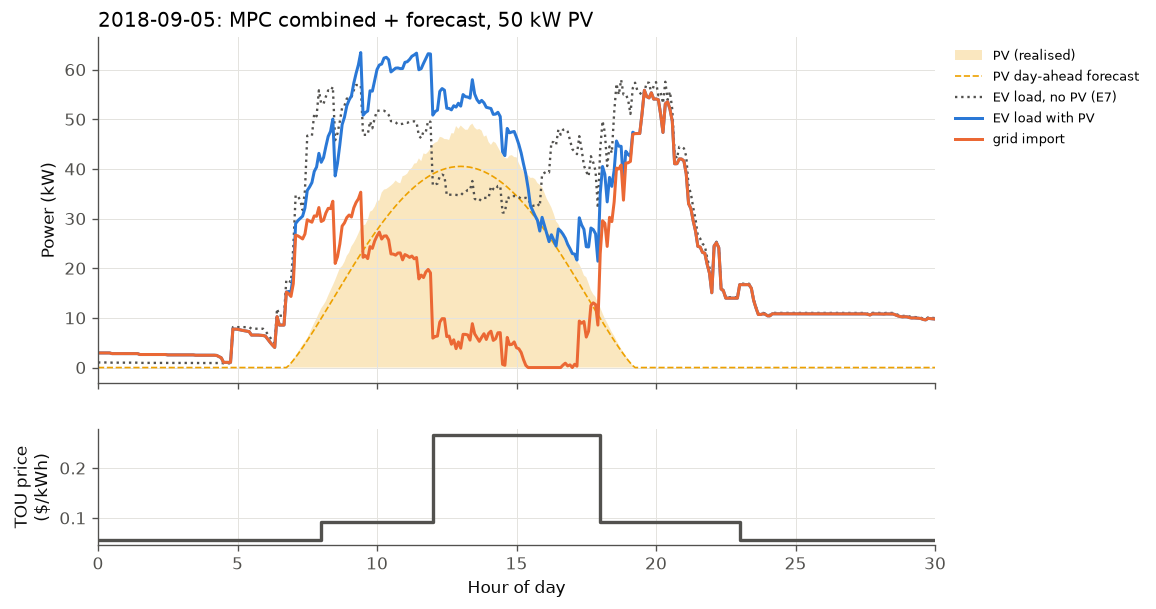

In [24]:
key = "mpc-combined_qp_forecast_hard=False.npz"
f4, f2 = RES / "traces" / "v4" / "perfect" / SHOWCASE / key, RES / "traces" / "v2" / SHOWCASE / key
if f4.exists():
    z = np.load(f4)
    p, pv = z["power"], z["pv"]
    imp = np.clip(p - pv, 0, None)
    fig, (ax, axp) = plt.subplots(2, 1, figsize=(9, 5.5), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
    h = hours(len(p))
    ax.fill_between(h, 0, pv, color=C[3], alpha=0.25, lw=0, label="PV (realised)")
    ax.plot(h, z["pv_day_ahead"], color=C[3], lw=1, ls="--", label="PV day-ahead forecast")
    if f2.exists():
        p2 = np.load(f2)["power"]
        ax.plot(hours(len(p2)), p2, color=MUTED, lw=1.4, ls=":", label="EV load, no PV (E7)")
    ax.plot(h, p, color=C[0], lw=1.8, label="EV load with PV")
    ax.plot(h, imp, color=C[1], lw=1.8, label="grid import")
    ax.set_ylabel("Power (kW)"); ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))
    ax.set_title(f"{SHOWCASE}: MPC combined + forecast, 50 kW PV", loc="left")
    axp.step(hours(len(prices)), prices, where="post", color=MUTED)
    axp.set_ylabel("TOU price\n($/kWh)"); axp.set_xlabel("Hour of day"); axp.set_xlim(0, 30)
    fig.savefig(FIG / "v4_solar_day.png"); plt.show()

## v4.4 Stochastic MPC with PV: delivery vs bill

The E8 extension's `stochastic-30` level (expected unmet energy over the EV's conditional (stay, kWh) scenarios at 30 $/kWh, finish-by dropped) rerun on the E9 month with 50 kW PV. Arrows run from predicted to stochastic-30. The offline bill LP with known PV is the grey star.

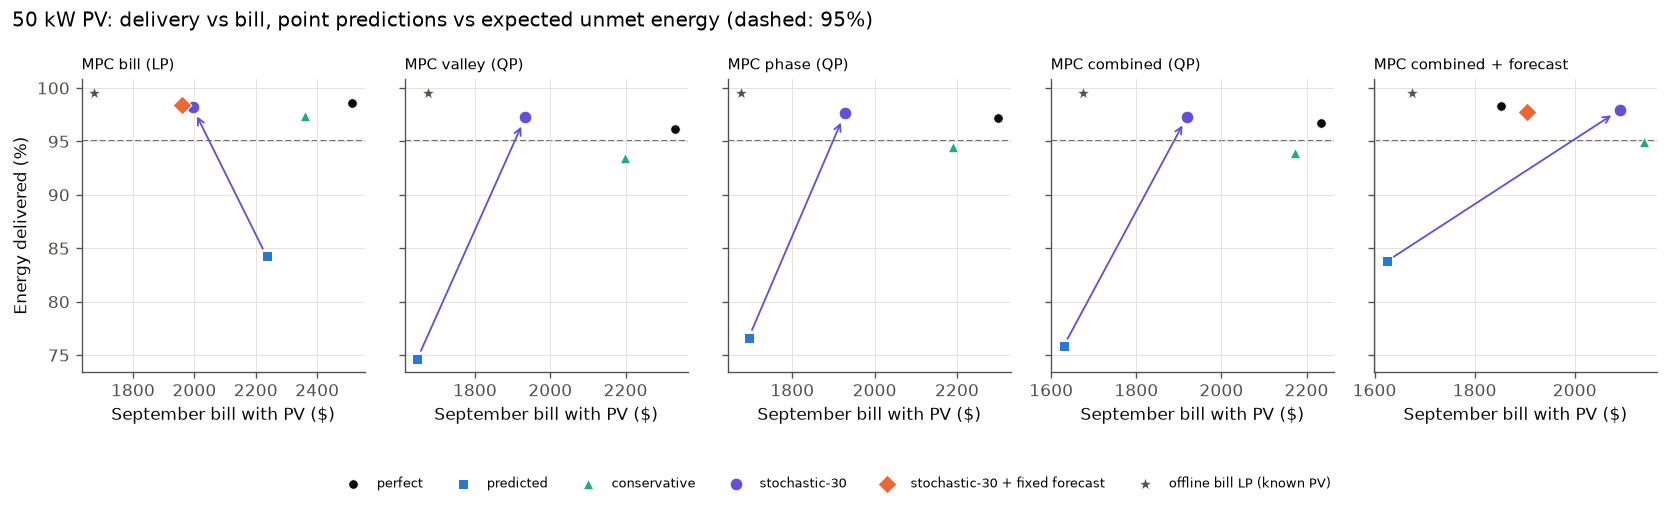

In [25]:
if ms is not None and (sol["info"] == "stochastic-30").any():
    st_algos = [a for a in order4 if a.startswith("mpc") and "+fix" not in a]
    FIXED = {"mpc:cost_lp": "mpc:cost_lp+forecast+fix", "mpc:combined_qp+forecast": "mpc:combined_qp+forecast+fix"}
    LEVEL_STYLE = {"perfect": (INK, "o", 34), "predicted": (C[0], "s", 34), "conservative": (C[2], "^", 40),
                   "stochastic-30": (C[6], "o", 58)}
    off = sol[sol.algo == "offline:cost_lp"]
    fig, axs = plt.subplots(1, len(st_algos), figsize=(14, 3.9), sharey=True)
    for ax, a in zip(axs, st_algos):
        d = sol[sol.algo == a].set_index("info")
        if {"predicted", "stochastic-30"} <= set(d.index):
            ax.annotate("", xy=(d.loc["stochastic-30", "bill_pv"], d.loc["stochastic-30", "delivered_pct"]),
                        xytext=(d.loc["predicted", "bill_pv"], d.loc["predicted", "delivered_pct"]),
                        arrowprops=dict(arrowstyle="->", color=C[6], lw=1.1, shrinkA=5, shrinkB=6), zorder=2)
        for lvl, (col, mk, sz) in LEVEL_STYLE.items():
            if lvl in d.index:
                ax.scatter(d.loc[lvl, "bill_pv"], d.loc[lvl, "delivered_pct"], s=sz, marker=mk, color=col,
                           edgecolor="white", linewidth=0.6, zorder=4, label=lvl)
        fx = sol[(sol.algo == FIXED.get(a)) & (sol["info"] == "stochastic-30")]
        if len(fx):
            ax.scatter(fx.bill_pv, fx.delivered_pct, s=64, marker="D", color=C[1], edgecolor="white",
                       linewidth=0.6, zorder=5, label="stochastic-30 + fixed forecast")
        if len(off):
            ax.scatter(off.bill_pv, off.delivered_pct, s=70, marker="*", color=MUTED, edgecolor="white",
                       linewidth=0.5, zorder=3, label="offline bill LP (known PV)")
        ax.axhline(95, color=MUTED, lw=1, ls="--", zorder=1)
        ax.set_title(LABELS4[a], loc="left", fontsize=9); ax.set_xlabel("September bill with PV ($)")
    axs[0].set_ylabel("Energy delivered (%)")
    hl = {}
    for ax in axs:
        for h_, l_ in zip(*ax.get_legend_handles_labels()):
            hl.setdefault(l_, h_)
    fig.legend(hl.values(), hl.keys(), loc="lower center", bbox_to_anchor=(0.5, -0.07), ncol=6, fontsize=8)
    fig.suptitle("50 kW PV: delivery vs bill, point predictions vs expected unmet energy (dashed: 95%)", x=0.01, ha="left")
    fig.tight_layout(rect=(0, 0.06, 1, 1)); fig.savefig(FIG / "v4_stochastic_frontier.png"); plt.show()

## v4.5 Showcase day with PV: combined MPC + forecast, predicted vs stochastic-30

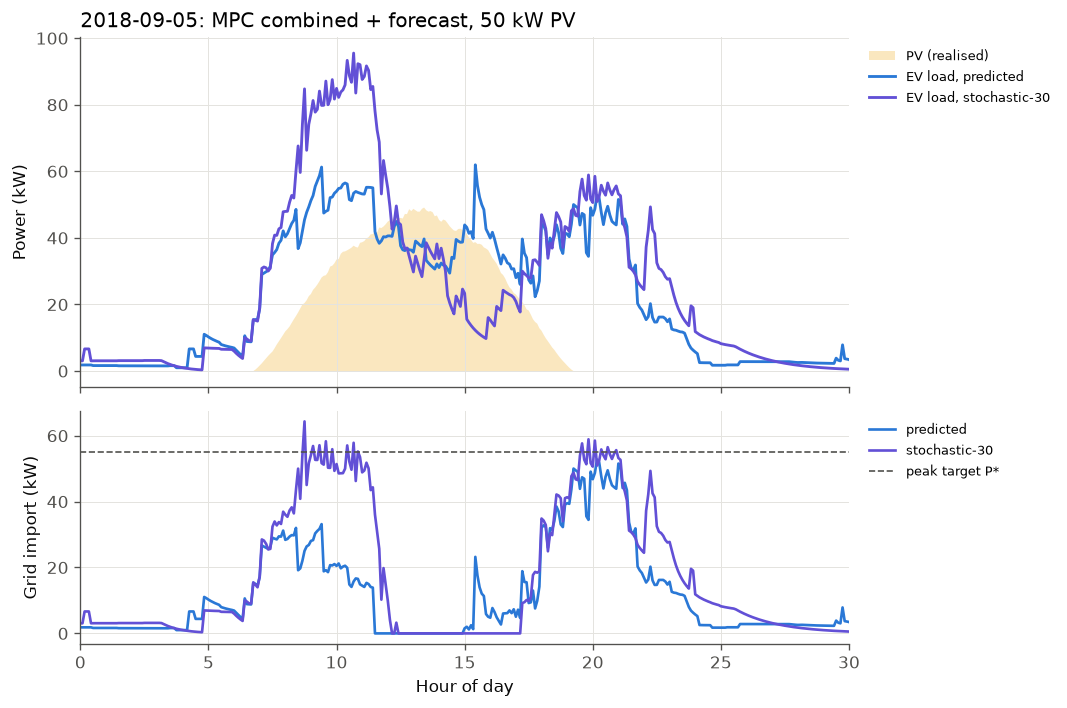

In [26]:
key = "mpc-combined_qp_forecast_hard=False.npz"
fs = {lvl: RES / "traces" / "v4" / lvl / SHOWCASE / key for lvl in ["predicted", "stochastic-30"]}
if all(f.exists() for f in fs.values()):
    import json
    pstar = json.loads((RES / "peak_target.json").read_text())["peak_target_kw"]
    fig, (ax, axi) = plt.subplots(2, 1, figsize=(9, 6), sharex=True, gridspec_kw={"height_ratios": [3, 2]})
    for lvl, col in [("predicted", C[0]), ("stochastic-30", C[6])]:
        z = np.load(fs[lvl])
        p, pv = z["power"], z["pv"]
        h = hours(len(p))
        if lvl == "predicted":
            ax.fill_between(h, 0, pv, color=C[3], alpha=0.25, lw=0, label="PV (realised)")
        ax.plot(h, p, color=col, lw=1.7, label=f"EV load, {lvl}")
        axi.plot(h, np.clip(p - pv, 0, None), color=col, lw=1.6, label=lvl)
    ax.set_ylabel("Power (kW)"); ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))
    ax.set_title(f"{SHOWCASE}: MPC combined + forecast, 50 kW PV", loc="left")
    axi.axhline(pstar, color=MUTED, ls="--", lw=1, label="peak target P*")
    axi.set_ylabel("Grid import (kW)"); axi.set_xlabel("Hour of day"); axi.set_xlim(0, 30)
    axi.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))
    fig.tight_layout(); fig.savefig(FIG / "v4_stochastic_day.png"); plt.show()

## v4.6 Forecast fix: the phantom horizon-edge peak on 24 September

Combined MPC + forecast at stochastic-30 with 50 kW PV, re-simulated for 24 September from the 61.5 kW month-to-date import peak, with the original ghost EVs and with `+fix`. Bottom: the highest billed power in each MPC step's 12 h plan; filled markers are steps where that planned peak is ghost load at the end of the horizon.

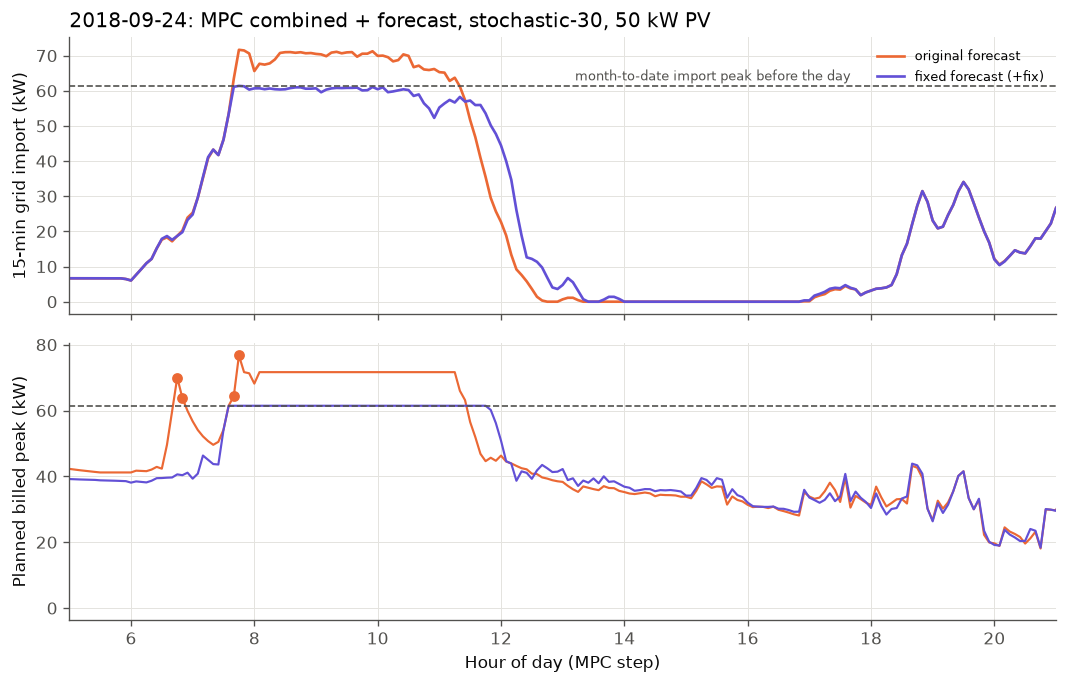

In [27]:
dg = RES / "diag_0924"
if (dg / "base_plan.csv").exists() and (dg / "fixed_plan.csv").exists():
    floor0 = 61.45
    fig, (ax, axp) = plt.subplots(2, 1, figsize=(9, 5.8), sharex=True, gridspec_kw={"height_ratios": [1, 1]})
    for name, col, lab in [("base", C[1], "original forecast"), ("fixed", C[6], "fixed forecast (+fix)")]:
        z = np.load(dg / f"{name}.npz")
        imp15 = pd.Series(np.clip(z["power"] - z["pv"], 0, None)).rolling(3).mean()
        ax.plot(hours(len(imp15)), imp15, color=col, lw=1.6, label=lab)
        p = pd.read_csv(dg / f"{name}_plan.csv")
        h = p.t * PERIOD / 60
        axp.plot(h, p.plan_peak, color=col, lw=1.3, label=lab)
        edge = (p.ghost_at > p.real_at) & (p.plan_peak > p.floor + 0.5)
        axp.scatter(h[edge], p.plan_peak[edge], color=col, s=30, zorder=3)
    for a_ in (ax, axp):
        a_.axhline(floor0, color=MUTED, ls="--", lw=1)
    ax.text(13.2, floor0 + 1.5, "month-to-date import peak before the day", fontsize=8, color=MUTED)
    ax.set_ylabel("15-min grid import (kW)"); ax.legend(fontsize=8, loc="upper right")
    ax.set_title("2018-09-24: MPC combined + forecast, stochastic-30, 50 kW PV", loc="left")
    axp.set_ylabel("Planned billed peak (kW)"); axp.set_xlabel("Hour of day (MPC step)"); axp.set_xlim(5, 21)
    fig.tight_layout(); fig.savefig(FIG / "v4_forecast_fix_day.png"); plt.show()